# Clasificación de imágenes y evaluación de la exactitud

Clasificar una imagen es asignar cada píxel, o cada objeto, a una clase temática: agua, bosque, pasto, suelo, roca, área urbana. Es la forma de convertir los valores espectrales en un mapa. Hay dos grandes enfoques. En la clasificación no supervisada, un algoritmo agrupa los píxeles por su similitud espectral y el analista identifica después qué cobertura corresponde a cada grupo. En la supervisada, el analista define primero las clases con áreas de entrenamiento de cobertura conocida y el algoritmo aprende a reconocerlas en el resto de la imagen {cite}`chuvieco2008,richards2013`.

Este capítulo usa la misma escena sintética del capítulo anterior, cuya verdad es conocida, para comparar los métodos y para mostrar cómo se evalúa un mapa.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage
plt.rcParams['figure.dpi'] = 100

BANDAS = ['azul', 'verde', 'rojo', 'NIR', 'SWIR1', 'SWIR2']
FIRMAS = {
    'agua':           [0.06, 0.05, 0.03, 0.01, 0.005, 0.003],
    'bosque':         [0.03, 0.06, 0.03, 0.38, 0.17, 0.07],
    'pasto':          [0.05, 0.09, 0.07, 0.30, 0.25, 0.14],
    'suelo desnudo':  [0.09, 0.13, 0.18, 0.25, 0.32, 0.27],
    'roca alterada':  [0.17, 0.22, 0.26, 0.31, 0.40, 0.24],
}
NOMBRES = list(FIRMAS)
CMAP = ListedColormap(['#2166ac', '#1b7837', '#a6d96a', '#d6a35c', '#bdbdbd'])

def escena(n=300, semilla=0, ruido=0.02):
    rng = np.random.default_rng(semilla)
    campos = [ndimage.gaussian_filter(rng.normal(0, 1, (n, n)), 12) for _ in FIRMAS]
    yy, xx = np.mgrid[0:n, 0:n]
    campos[0] += 4 * np.exp(-((xx - 0.25 * n)**2 + (yy - 0.75 * n)**2) / (0.12 * n)**2) - 1.5
    campos[4] += 3 * np.exp(-((xx - 0.75 * n)**2 + (yy - 0.25 * n)**2) / (0.15 * n)**2) - 1.0
    clases = np.argmax(np.array(campos), axis=0)
    img = np.zeros((len(BANDAS), n, n))
    for k, f in enumerate(FIRMAS.values()):
        m = clases == k
        variab = 1 + 0.15 * ndimage.gaussian_filter(rng.normal(0, 1, (n, n)), 3)[m]
        for b in range(len(BANDAS)):
            img[b][m] = f[b] * variab
    img = ndimage.gaussian_filter(img, (0, 1.2, 1.2))                     # píxeles mezclados en los bordes
    iluminacion = 1 + 0.25 * ndimage.gaussian_filter(rng.normal(0, 1, (n, n)), 4) / 0.05   # efecto del relieve
    img = img * np.clip(iluminacion, 0.55, 1.45) + rng.normal(0, ruido, img.shape)
    return np.clip(img, 0, 1), clases

img, verdad = escena()
nb, n, _ = img.shape
X = img.reshape(nb, -1).T
y = verdad.ravel()

## El espacio espectral

Cada píxel es un punto en un espacio de tantas dimensiones como bandas. Las coberturas forman nubes de puntos en ese espacio, y clasificar es dividirlo en regiones. La gráfica siguiente muestra la proyección en el plano rojo-infrarrojo cercano, el más usado para vegetación: el agua queda cerca del origen, la vegetación arriba a la izquierda y los suelos y las rocas a lo largo de la línea de suelos. Se ve que el pasto y el suelo desnudo se traslapan en este plano; con las bandas del infrarrojo de onda corta se separan mejor.

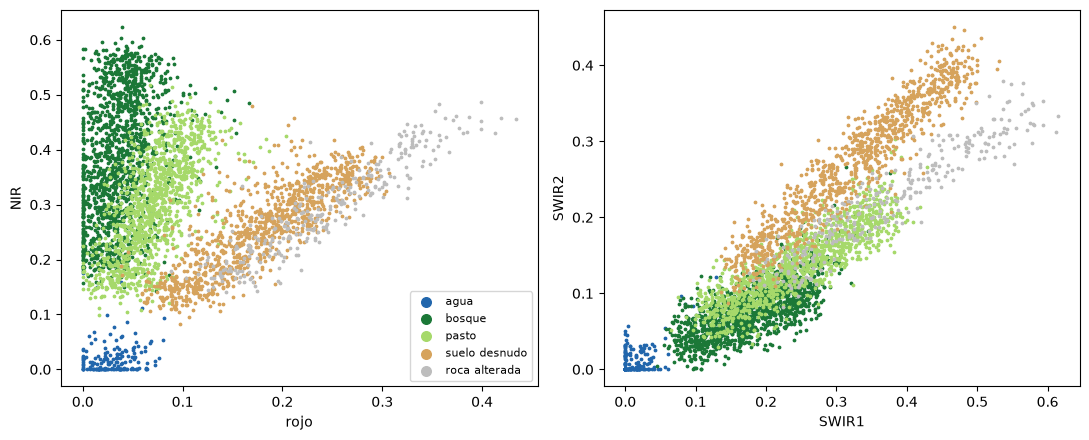

In [2]:
rng = np.random.default_rng(1)
muestra = rng.choice(X.shape[0], 4000, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for k, nom in enumerate(NOMBRES):
    m = y[muestra] == k
    ax[0].scatter(X[muestra][m, 2], X[muestra][m, 3], s=3, color=CMAP(k), label=nom)
    ax[1].scatter(X[muestra][m, 4], X[muestra][m, 5], s=3, color=CMAP(k))
ax[0].set_xlabel('rojo'); ax[0].set_ylabel('NIR'); ax[0].legend(markerscale=4, fontsize=8)
ax[1].set_xlabel('SWIR1'); ax[1].set_ylabel('SWIR2')
plt.tight_layout(); plt.show()

## Clasificación no supervisada: k-medias

El algoritmo de k-medias agrupa los píxeles en $k$ grupos: parte de $k$ centros iniciales, asigna cada píxel al centro más cercano, recalcula los centros como la media de sus píxeles y repite hasta que los grupos no cambian. ISODATA es una variante que además divide los grupos muy dispersos y une los muy cercanos. El resultado son grupos espectrales, no clases temáticas: el analista debe etiquetarlos, y a menudo una cobertura se divide en varios grupos (por ejemplo, laderas iluminadas y en sombra) o varias coberturas caen en uno solo. Por eso se suele pedir más grupos que clases y luego agruparlos.

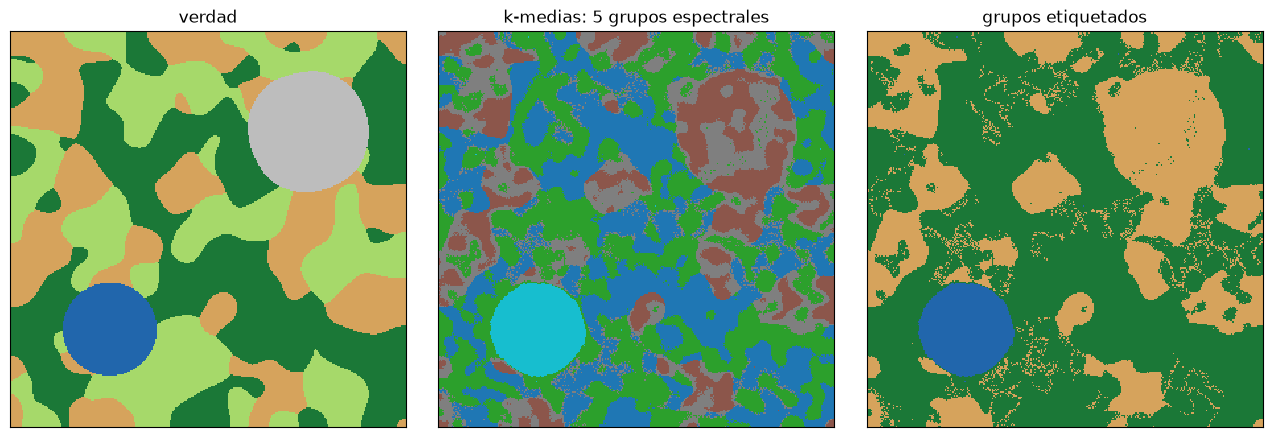

In [3]:
from sklearn.cluster import KMeans
km = KMeans(n_clusters=5, n_init=5, random_state=0).fit(X[::7])
grupos = km.predict(X).reshape(n, n)
# etiquetado: cada grupo recibe la clase verdadera más frecuente (en la práctica lo hace el analista)
etiqueta = {g: np.bincount(verdad[grupos == g], minlength=5).argmax() for g in range(5)}
no_sup = np.vectorize(etiqueta.get)(grupos)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.3))
axs[0].imshow(verdad, cmap=CMAP, vmin=0, vmax=4, interpolation='nearest'); axs[0].set_title('verdad')
axs[1].imshow(grupos, cmap='tab10', interpolation='nearest'); axs[1].set_title('k-medias: 5 grupos espectrales')
axs[2].imshow(no_sup, cmap=CMAP, vmin=0, vmax=4, interpolation='nearest'); axs[2].set_title('grupos etiquetados')
for a in axs: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Clasificación supervisada

En la clasificación supervisada se digitalizan áreas de entrenamiento representativas de cada clase, distribuidas por toda la imagen y con suficientes píxeles (como regla, al menos 10 a 30 veces el número de bandas por clase). Con ellas se entrena un clasificador. Los clásicos son la mínima distancia, que asigna cada píxel a la clase de media más cercana, y la máxima verosimilitud, que modela cada clase como una distribución normal multivariada con su media y su matriz de covarianza y asigna cada píxel a la clase más probable; es el clasificador estadístico estándar en teledetección. Los métodos de aprendizaje automático, como el bosque aleatorio (random forest) o las máquinas de soporte vectorial, no suponen ninguna distribución y suelen dar mejores resultados con clases complejas; las redes neuronales convolucionales, además, aprenden del contexto espacial de cada píxel.

La celda siguiente simula la toma de áreas de entrenamiento como pequeños polígonos, entrena tres clasificadores (mínima distancia, máxima verosimilitud, que equivale al análisis discriminante cuadrático, y bosque aleatorio) y los aplica a toda la escena.

1470 píxeles de entrenamiento: [294 294 294 294 294]


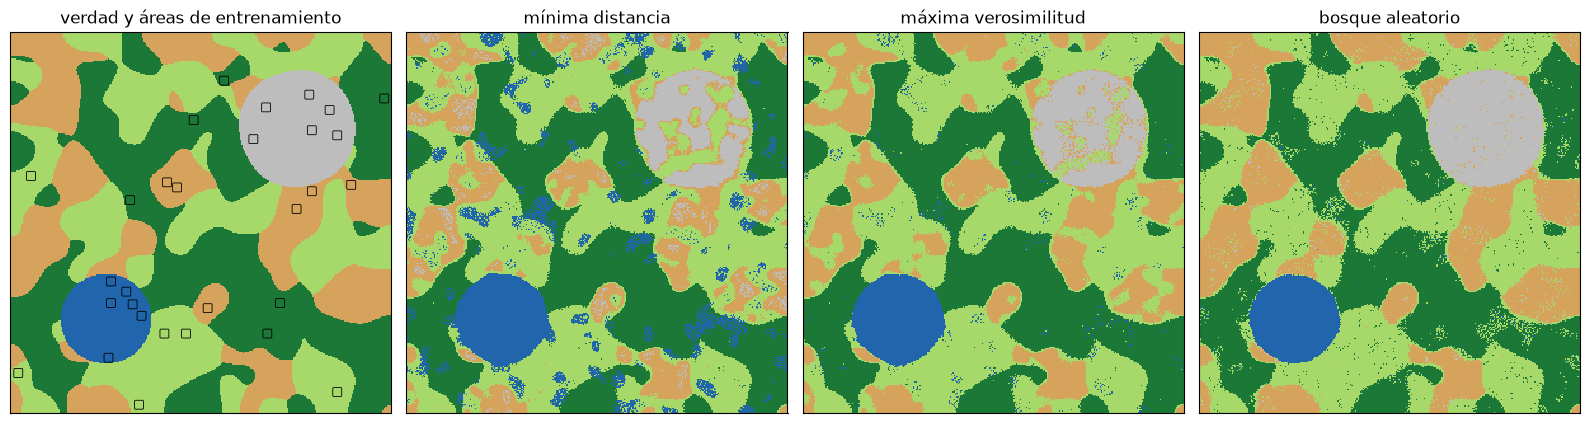

In [4]:
from sklearn.neighbors import NearestCentroid
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier

entren = np.zeros((n, n), bool)
for k in range(5):
    filas, cols = np.where(ndimage.binary_erosion(verdad == k, iterations=4))
    for j in rng.choice(len(filas), 6, replace=False):                 # 6 polígonos de 7x7 por clase
        entren[filas[j] - 3:filas[j] + 4, cols[j] - 3:cols[j] + 4] = True
X_tr, y_tr = X[entren.ravel()], y[entren.ravel()]
print(f'{entren.sum()} píxeles de entrenamiento:', np.bincount(y_tr))

clasif = {'mínima distancia': NearestCentroid(),
          'máxima verosimilitud': QuadraticDiscriminantAnalysis(reg_param=0.01),
          'bosque aleatorio': RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)}
mapas = {nom: c.fit(X_tr, y_tr).predict(X).reshape(n, n) for nom, c in clasif.items()}
fig, axs = plt.subplots(1, 4, figsize=(16, 4.3))
axs[0].imshow(verdad, cmap=CMAP, vmin=0, vmax=4, interpolation='nearest'); axs[0].contour(entren, [0.5], colors='k', linewidths=0.6)
axs[0].set_title('verdad y áreas de entrenamiento')
for a, (nom, m) in zip(axs[1:], mapas.items()):
    a.imshow(m, cmap=CMAP, vmin=0, vmax=4, interpolation='nearest'); a.set_title(nom)
for a in axs: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Evaluación de la exactitud

Un mapa sin evaluación de su exactitud no se debe usar. La evaluación compara la clase asignada con la verdad de terreno en una muestra de puntos de validación independientes de los de entrenamiento, elegidos con un muestreo aleatorio, estratificado por clase o sistemático {cite}`congalton1991`. El resultado se resume en la matriz de confusión, que cruza las clases de referencia con las clasificadas. De ella salen la exactitud global, la proporción de puntos bien clasificados; la exactitud del productor de cada clase, la proporción de puntos de referencia de esa clase que el mapa acertó (su complemento es el error de omisión); y la exactitud del usuario, la proporción de puntos clasificados en esa clase que realmente la tienen (su complemento es el error de comisión). El índice kappa de Cohen compara la exactitud observada $p_o$ con la que se esperaría por azar $p_e$:

$$\kappa = \frac{p_o - p_e}{1 - p_e}.$$

La celda siguiente calcula todo esto a mano para el bosque aleatorio y compara los tres clasificadores.

In [5]:
def matriz_confusion(ref, pred, k=5):
    M = np.zeros((k, k), int)
    np.add.at(M, (pred, ref), 1)       # filas: clasificado; columnas: referencia
    return M

def evaluar(M):
    total = M.sum()
    po = np.trace(M) / total
    pe = (M.sum(0) * M.sum(1)).sum() / total**2
    with np.errstate(invalid='ignore', divide='ignore'):        # una clase puede no recibir ningún píxel
        return po, (po - pe) / (1 - pe), np.diag(M) / M.sum(0), np.diag(M) / M.sum(1)

valid = rng.choice(np.where(~entren.ravel())[0], 1000, replace=False)   # puntos de validación aleatorios
M = matriz_confusion(y[valid], mapas['bosque aleatorio'].ravel()[valid])
po, kappa, prod, usu = evaluar(M)
print('Matriz de confusión del bosque aleatorio (filas: clasificado, columnas: referencia)')
print(' ' * 15 + ''.join(f'{nm[:9]:>10s}' for nm in NOMBRES) + '     total')
for k, nm in enumerate(NOMBRES):
    print(f'{nm:15s}' + ''.join(f'{v:10d}' for v in M[k]) + f'{M[k].sum():10d}')
print(f'\nExactitud global {po:.3f}, kappa {kappa:.3f}')
for k, nm in enumerate(NOMBRES):
    print(f'  {nm:15s} productor {prod[k]:.2f} (omisión {1-prod[k]:.2f})   usuario {usu[k]:.2f} (comisión {1-usu[k]:.2f})')
print()
for nom, m in list(mapas.items()) + [('k-medias etiquetado', no_sup)]:
    po_, k_, *_ = evaluar(matriz_confusion(y[valid], m.ravel()[valid]))
    print(f'{nom:22s} exactitud global {po_:.3f}   kappa {k_:.3f}')

Matriz de confusión del bosque aleatorio (filas: clasificado, columnas: referencia)
                     agua    bosque     pasto suelo des roca alte     total
agua                   43         2         0         0         0        45
bosque                  0       293         6         0         0       299
pasto                   2        23       296        20         1       342
suelo desnudo           0         0         6       231         2       239
roca alterada           0         1         1         3        70        75

Exactitud global 0.933, kappa 0.908
  agua            productor 0.96 (omisión 0.04)   usuario 0.96 (comisión 0.04)
  bosque          productor 0.92 (omisión 0.08)   usuario 0.98 (comisión 0.02)
  pasto           productor 0.96 (omisión 0.04)   usuario 0.87 (comisión 0.13)
  suelo desnudo   productor 0.91 (omisión 0.09)   usuario 0.97 (comisión 0.03)
  roca alterada   productor 0.96 (omisión 0.04)   usuario 0.93 (comisión 0.07)

mínima distancia       exac

## Posclasificación

Los mapas por píxel suelen tener un efecto de sal y pimienta: píxeles aislados mal clasificados dentro de áreas homogéneas. Un filtro de moda (o de mayoría), que asigna a cada píxel la clase más frecuente en su vecindad, los elimina y produce un mapa más limpio, a costa de perder rasgos muy pequeños. Otra alternativa es la clasificación orientada a objetos, que primero segmenta la imagen en regiones homogéneas y luego clasifica las regiones usando también su forma, su textura y su contexto. La celda siguiente aplica un filtro de moda al resultado de la mínima distancia.

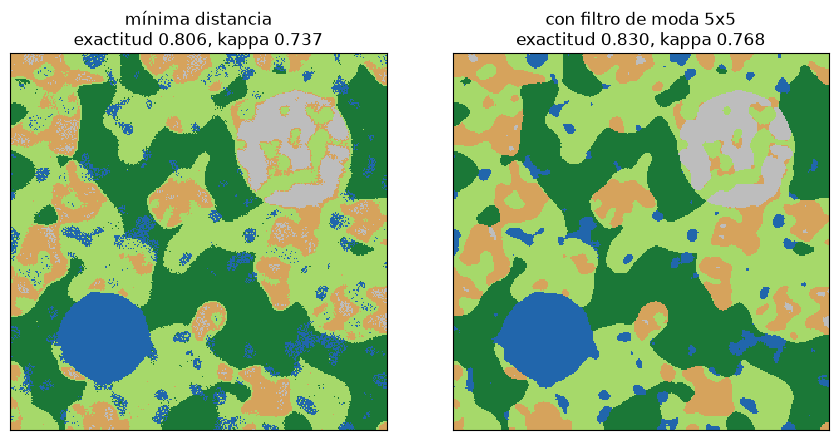

In [6]:
def filtro_moda(m, tam=5):
    conteos = np.array([ndimage.uniform_filter((m == k).astype(float), tam) for k in range(5)])
    return conteos.argmax(axis=0)

md = mapas['mínima distancia']
md_f = filtro_moda(md)
fig, axs = plt.subplots(1, 2, figsize=(9, 4.4))
for a, m, t in zip(axs, [md, md_f], ['mínima distancia', 'con filtro de moda 5x5']):
    po_, k_, *_ = evaluar(matriz_confusion(y[valid], m.ravel()[valid]))
    a.imshow(m, cmap=CMAP, vmin=0, vmax=4, interpolation='nearest'); a.set_title(f'{t}\nexactitud {po_:.3f}, kappa {k_:.3f}')
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Para profundizar

Los capítulos 7 a 9 de {cite}`richards2013` cubren la clasificación supervisada y no supervisada con todo detalle, y el capítulo 7 de {cite}`chuvieco2008` la presenta con ejemplos. Para la evaluación de la exactitud, el artículo de {cite:t}`congalton1991` es la referencia básica. Los notebooks del curso con redes neuronales (ANN y CNN) y con la cartografía de movimientos en masa, listados en el apéndice {doc}`A_Practicas`, aplican estos métodos a imágenes reales.